# 1) Chargement des données

Allez, cadeau 😘:

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


DATA_PATH = "billets.csv"

if not os.path.exists(DATA_PATH):
    print(f"❌ Attention : le fichier '{DATA_PATH}' n'existe pas.")

try:
    df = pd.read_csv(DATA_PATH, sep=";")
    print("✅ Données chargées :", df.shape)
    display(df.head())
except Exception as e:
    print("❌ Erreur lors du chargement :", e)
    print("⚠️ Tu as bien lu le code avant de l'executer ? 😏")


✅ Données chargées : (1500, 7)


,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


# 2) Analyse exploratoire (EDA)


Là, c'est vous les pro 💪, je vous fais entièrement confiance 😉 !

Pssst (indice) : trouvez des variables corrélées à votre objectif, ça marche mieux 😉.

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   is_genuine    1500 non-null   bool   
 1   diagonal      1500 non-null   float64
 2   height_left   1500 non-null   float64
 3   height_right  1500 non-null   float64
 4   margin_low    1463 non-null   float64
 5   margin_up     1500 non-null   float64
 6   length        1500 non-null   float64
dtypes: bool(1), float64(6)
memory usage: 71.9 KB


In [3]:
df.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1500.000000,1500.000000,1500.000000,1463.000000,1500.000000,1500.00000
mean,171.958440,104.029533,103.920307,4.485967,3.151473,112.67850
std,0.305195,0.299462,0.325627,0.663813,0.231813,0.87273
min,171.040000,103.140000,102.820000,2.980000,2.270000,109.49000
25%,171.750000,103.820000,103.710000,4.015000,2.990000,112.03000
50%,171.960000,104.040000,103.920000,4.310000,3.140000,112.96000
75%,172.170000,104.230000,104.150000,4.870000,3.310000,113.34000
max,173.010000,104.880000,104.950000,6.900000,3.910000,114.44000


In [4]:
count_true = (df["is_genuine"] == True).sum()
print("There are", count_true, "true bills.")
count_false = (df["is_genuine"] == False).sum()
print("There are", count_false, "false bills.")

There are 1000 true bills.
There are 500 false bills.


In [5]:
df[df["is_genuine"] == True].describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1000.000000,1000.000000,1000.00000,971.000000,1000.00000,1000.000000
mean,171.987080,103.949130,103.80865,4.116097,3.05213,113.202430
std,0.300441,0.300231,0.29157,0.319124,0.18634,0.359552
min,171.040000,103.140000,102.82000,2.980000,2.27000,111.760000
25%,171.790000,103.740000,103.61000,3.905000,2.93000,112.950000
50%,171.990000,103.950000,103.81000,4.110000,3.05000,113.205000
75%,172.200000,104.140000,104.00000,4.340000,3.18000,113.460000
max,172.920000,104.860000,104.95000,5.040000,3.74000,114.440000


In [6]:
df[df["is_genuine"] == False].describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,500.000000,500.000000,500.000000,492.000000,500.000000,500.000000
mean,171.901160,104.190340,104.143620,5.215935,3.350160,111.630640
std,0.306861,0.223758,0.270878,0.553531,0.180498,0.615543
min,171.040000,103.510000,103.430000,3.820000,2.920000,109.490000
25%,171.690000,104.040000,103.950000,4.840000,3.220000,111.200000
50%,171.910000,104.180000,104.160000,5.190000,3.350000,111.630000
75%,172.092500,104.332500,104.320000,5.592500,3.472500,112.030000
max,173.010000,104.880000,104.950000,6.900000,3.910000,113.850000


In [7]:
df[df["is_genuine"] == True].head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
0,True,171.81,104.86,104.95,4.52,2.89,112.83
1,True,171.46,103.36,103.66,3.77,2.99,113.09
2,True,172.69,104.48,103.50,4.40,2.94,113.16
3,True,171.36,103.91,103.94,3.62,3.01,113.51
4,True,171.73,104.28,103.46,4.04,3.48,112.54


In [8]:
df[df["is_genuine"] == False].head()

,is_genuine,diagonal,height_left,height_right,margin_low,margin_up,length
1000,False,172.28,103.95,103.91,4.78,3.31,111.40
1001,False,171.92,103.86,104.30,4.96,3.13,111.29
1002,False,171.59,104.14,104.38,4.97,3.47,111.22
1003,False,172.02,104.33,104.33,5.19,3.21,111.99
1004,False,172.55,104.25,104.23,5.60,3.13,111.72


In [9]:
df.isna().sum()

is_genuine       0
diagonal         0
height_left      0
height_right     0
margin_low      37
margin_up        0
length           0
dtype: int64

In [10]:
df[df["is_genuine"] == True]["margin_low"].isna().sum()

np.int64(29)

In [11]:
df[df["is_genuine"] == False]["margin_low"].isna().sum()

np.int64(8)

**On va supprimer de l'analyse les billets ne contenant pas de margin_low.**

In [12]:
df_final = df[~df["margin_low"].isna()]

In [13]:
df_final.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1463.000000,1463.000000,1463.000000,1463.000000,1463.000000,1463.000000
mean,171.959193,104.031333,103.921476,4.485967,3.153083,112.674757
std,0.305457,0.299605,0.324181,0.663813,0.231466,0.873222
min,171.040000,103.140000,102.910000,2.980000,2.270000,109.490000
25%,171.750000,103.825000,103.710000,4.015000,2.990000,112.020000
50%,171.960000,104.040000,103.920000,4.310000,3.140000,112.960000
75%,172.170000,104.230000,104.150000,4.870000,3.315000,113.340000
max,173.010000,104.880000,104.950000,6.900000,3.910000,114.320000


In [14]:
billet_authentique = df[df["is_genuine"] == True].iloc[0]

billet_authentique

is_genuine        True
diagonal        171.81
height_left     104.86
height_right    104.95
margin_low        4.52
margin_up         2.89
length          112.83
Name: 0, dtype: object

In [15]:
corr = df_final.corr(numeric_only=True)["is_genuine"].sort_values(ascending=False)

print(corr)

is_genuine      1.000000
length          0.850223
diagonal        0.134720
height_left    -0.373624
height_right   -0.487177
margin_up      -0.610412
margin_low     -0.783032
Name: is_genuine, dtype: float64


Plusieurs caractéristiques sont associées à l'authenticité des billets : 
- length présente la corrélation positive la plus élevée (0,85), 
- margin_low présente une forte corrélation négative (-0,78),
- diagonal est faiblement corrélée à la cible (0,13).

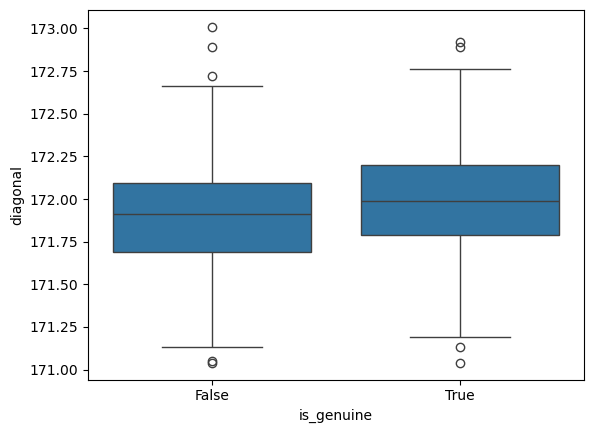

In [16]:
sns.boxplot(data=df, x="is_genuine", y="diagonal")
plt.show()

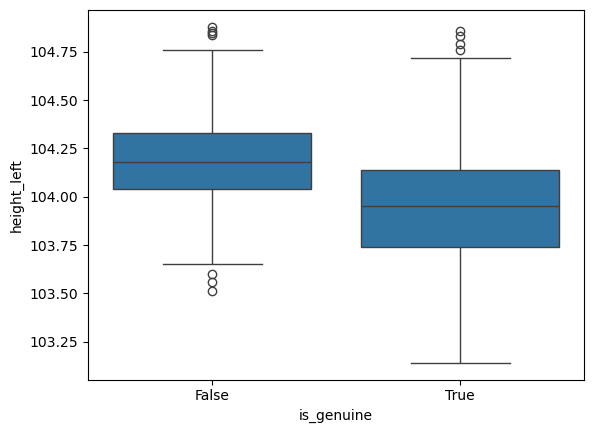

In [17]:
sns.boxplot(data=df, x="is_genuine", y="height_left")
plt.show()

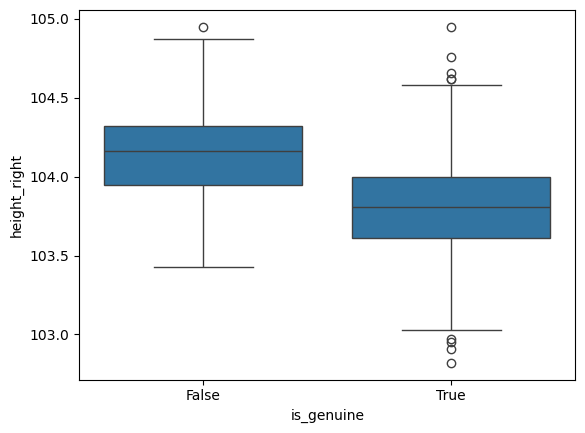

In [18]:
sns.boxplot(data=df, x="is_genuine", y="height_right")
plt.show()

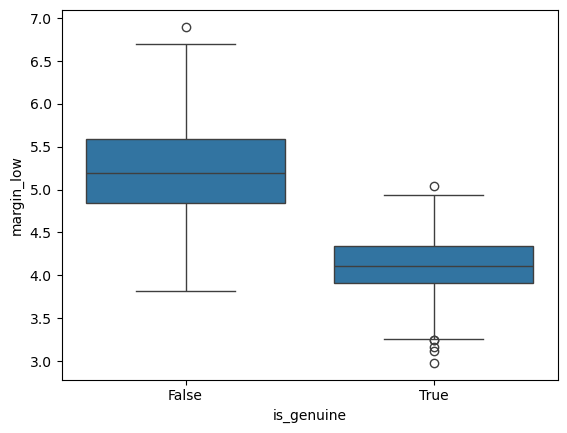

In [19]:
sns.boxplot(data=df, x="is_genuine", y="margin_low")
plt.show()

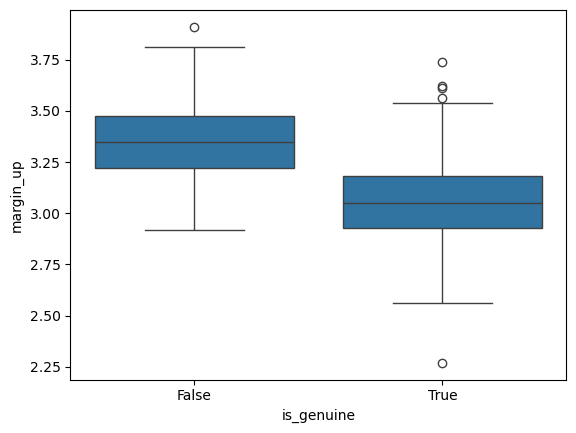

In [20]:
sns.boxplot(data=df, x="is_genuine", y="margin_up")
plt.show()

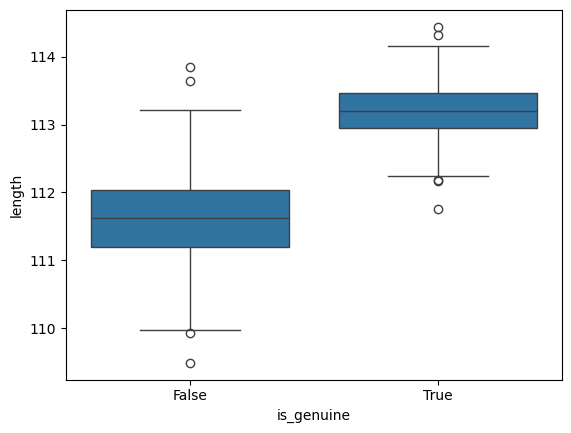

In [21]:
sns.boxplot(data=df, x="is_genuine", y="length")
plt.show()

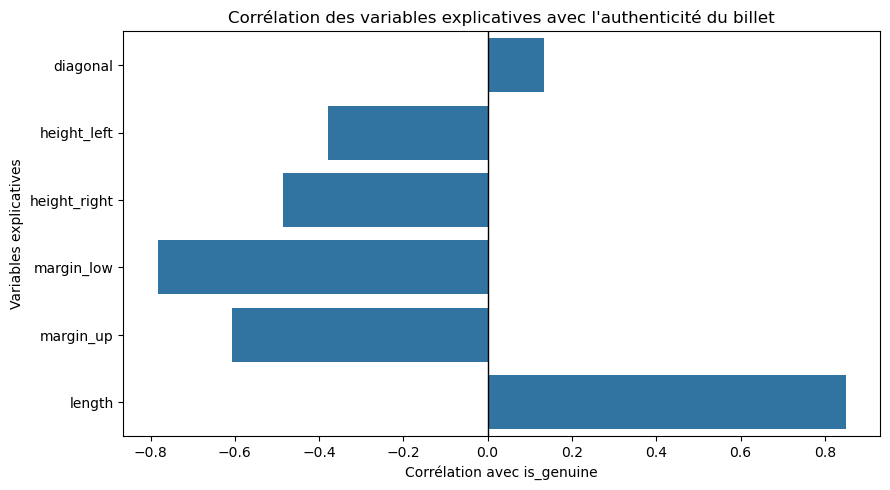

In [22]:
corr = df.corr(numeric_only=True)["is_genuine"].drop("is_genuine")

plt.figure(figsize=(9, 5))

sns.barplot(
    x=corr.values,
    y=corr.index
)

plt.axvline(0, color="black", linewidth=1)
plt.xlabel("Corrélation avec is_genuine")
plt.ylabel("Variables explicatives")
plt.title("Corrélation des variables explicatives avec l'authenticité du billet")

plt.tight_layout()
plt.show()

# 3) Prétraitement

Le but est de transformer tes données brutes (les valeurs mesurées des billets) en données que les algorithmes de Machine Learning peuvent comprendre efficacement.


D'abord, il faut séparer les variables explicatives et la cible :

X = les mesures du billet (longueur, hauteur, diagonales…)

y = l’étiquette (vrai ou faux)

➡️ Pourquoi ?
Parce que le modèle doit apprendre à prédire y en fonction de X.

In [23]:
X = df_final.drop(columns=["is_genuine"]) # Toutes les colonnes sauf la cible
y = df_final["is_genuine"] # La colonne cible

In [24]:
X.describe()

,diagonal,height_left,height_right,margin_low,margin_up,length
count,1463.000000,1463.000000,1463.000000,1463.000000,1463.000000,1463.000000
mean,171.959193,104.031333,103.921476,4.485967,3.153083,112.674757
std,0.305457,0.299605,0.324181,0.663813,0.231466,0.873222
min,171.040000,103.140000,102.910000,2.980000,2.270000,109.490000
25%,171.750000,103.825000,103.710000,4.015000,2.990000,112.020000
50%,171.960000,104.040000,103.920000,4.310000,3.140000,112.960000
75%,172.170000,104.230000,104.150000,4.870000,3.315000,113.340000
max,173.010000,104.880000,104.950000,6.900000,3.910000,114.320000


In [25]:
y.describe()

count     1463
unique       2
top       True
freq       971
Name: is_genuine, dtype: object

Autre point important : on entraîne toujours le modèle sur un morceau des données, et on teste sur un autre qu’il n’a jamais vu.

➡️ Pourquoi ?
Pour éviter le sur-apprentissage (le modèle apprend par cœur sans savoir généraliser).

In [26]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=100
)

In [27]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1170, 6)
(293, 6)
(1170,)
(293,)


Enfin, on met toutes les variables sur la même échelle (moyenne = 0, écart-type = 1).

➡️ Pourquoi ?
Parce que certains modèles, comme le KNN ou la Régression Logistique, sont sensibles aux différences d’échelle.
Sans standardisation, la variable la plus grande numériquement prend trop d’importance.

In [28]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
# Use scaler on X_train and X_test.

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [29]:
print(X_train)
print(X_test)

[[-0.28569336  2.28678221 -0.23120684 -0.19374472 -1.9076416   1.18509614]
 [ 0.52870394 -0.44345892  1.23608272 -0.99181234 -0.53125453  1.01340546]
 [ 0.85446286 -0.94905913 -0.10633113 -0.46478655  0.15693901  0.76159246]
 ...
 [ 0.26809681 -0.27492552  0.51804741 -0.01305016 -2.33776256  0.30375065]
 [-0.22054157 -2.06137959 -1.79215318  0.64949654 -0.57426662  0.60134783]
 [ 1.0824941  -0.27492552  0.20585814 -0.9466387  -1.39149645  0.77303851]]
[[-1.7190326   1.4441152   0.08098243  0.96571201 -0.44523034 -1.68786123]
 [-0.96978708 -0.94905913  0.45560955 -0.72077051 -0.74631501  0.91039105]
 [ 1.01734232  0.09584797 -0.66827181 -1.12733326  0.2429632   0.9218371 ]
 ...
 [-1.03493887 -1.45465934 -0.51217718 -0.10339744 -0.74631501  0.30375065]
 [ 1.86431551 -0.20751215 -2.01068567  0.18270227  1.10320512  0.65857805]
 [-0.54630049 -1.58948606 -0.48095825 -0.50996019 -1.52053273 -0.00529257]]


In [30]:
idx = ["mean", "std"]

pd.DataFrame(X_train).describe().round(2).loc[idx, :]

,0,1,2,3,4,5
mean,-0.0,0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0


# 4) Modélisation

Dans tous domaines, vous ne pouvez pas progresser si vous ne comprenez pas comment vos outils fonctionnent.

Avant d'utiliser les modèles mathématiques qui suivent, je vous recommande donc de visionner les vidéos suivantes:
* [StatQuest: Logistic Regression](https://www.youtube.com/watch?v=yIYKR4sgzI8)
* [StatQuest: K-nearest neighbors, Clearly Explained](https://youtu.be/HVXime0nQeI)
* [StatQuest: Random Forests Part 1 - Building, Using and Evaluating](https://youtu.be/J4Wdy0Wc_xQ)
* [StatQuest: Random Forests Part 2: Missing data and clustering](https://www.youtube.com/watch?v=sQ870aTKqiM)
* [StatQuest: K-means clustering](https://youtu.be/4b5d3muPQmA)

In [31]:
from sklearn.linear_model import LogisticRegression

# 1) Initialisez une régression logistic.
    # Quels sont les paramètres ajustables de ce modèle ?
    # Bien que vous puissez laisser la majorité d'entre eux par défaut,
    # il vaut mieux, à minima, ajuster `max_iter` pour plafonner le temps de calcul.

# max_iter, l1_ratio, C, solver

logreg = LogisticRegression(
    max_iter=1000,
    C=1.0,
    solver="lbfgs",
    random_state=100
)

# 2) Entrainez le modèle avec vos données X_train et y_train
logreg.fit(X_train, y_train)

# 3) Utiliser la régression logistique pour déterminer les vrais / faux billets de X_test.
y_pred_logreg = logreg.predict(X_test)
print(y_pred_logreg)


[False  True  True  True  True  True False  True  True  True  True False
 False  True  True  True  True  True  True  True  True  True False  True
  True False  True  True  True False False False False  True  True False
  True  True False  True  True False  True  True  True  True False False
  True False False  True  True False  True  True  True  True False  True
 False  True  True  True  True False False  True  True  True  True False
 False  True  True False  True  True  True False False  True  True False
  True  True  True False  True  True  True  True  True  True  True  True
  True False  True  True False  True  True False  True  True  True  True
  True False  True  True  True  True  True  True  True  True False False
  True  True  True False  True  True  True  True  True  True  True False
  True  True  True False  True False  True False  True  True False False
 False False  True  True  True  True False  True  True False False  True
  True  True False False  True  True False  True Fa

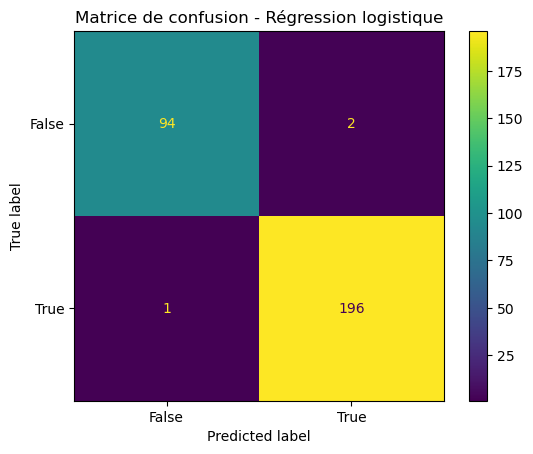

In [32]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_logreg)

plt.title("Matrice de confusion - Régression logistique")
plt.show()

Haut-Gauche : faux billet identifié comme faux

Bas-Droite : vrai billet identifié comme vrai

Bas-Gauche : vrai billet classé comme faux

Haut-Droite : faux billet classé comme vrai

In [33]:
from sklearn.neighbors import KNeighborsClassifier

# Répéter les même étapes que pour la régression logistique mais avec le KNN.

knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)




,n_neighbors,3
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [34]:
y_pred = knn.predict(X_test)

In [35]:
from sklearn.metrics import accuracy_score, precision_score, recall_score

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)

Accuracy: 0.9897610921501706


In [36]:
from sklearn.model_selection import cross_val_score

k_values = [i for i in range (1,31)]
scores = []

scaler = StandardScaler()
X = scaler.fit_transform(X)

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    score = cross_val_score(knn, X, y, cv=5)
    scores.append(np.mean(score))

Text(0, 0.5, 'Accuracy Score')

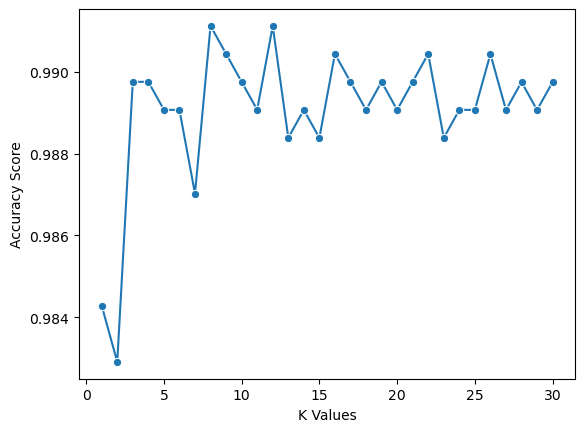

In [37]:
sns.lineplot(x = k_values, y = scores, marker = 'o')
plt.xlabel("K Values")
plt.ylabel("Accuracy Score")



In [38]:
best_index = np.argmax(scores)
best_k = k_values[best_index]

knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)

,n_neighbors,8
,weights,'uniform'
,algorithm,'auto'
,leaf_size,30
,p,2
,metric,'minkowski'
,metric_params,None
,n_jobs,None


In [39]:
y_pred_knn = knn.predict(X_test)

accuracy = accuracy_score(y_test, y_pred_knn)
precision = precision_score(y_test, y_pred_knn)
recall = recall_score(y_test, y_pred_knn)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)

Accuracy: 0.9897610921501706
Precision: 0.98989898989899
Recall: 0.9949238578680203


In [40]:
print(y_pred_knn)

[False  True  True  True  True  True False  True  True  True  True False
 False  True  True  True  True  True  True  True  True  True False  True
  True False  True  True  True False False False False  True  True False
  True  True False  True  True False  True  True  True  True False False
  True False False  True  True False  True  True  True  True False  True
 False  True  True  True  True False False  True  True  True  True False
 False  True  True False  True  True  True False False  True  True False
  True  True  True False  True  True  True  True  True  True  True  True
  True False  True  True False  True  True False  True  True  True  True
  True False  True  True  True  True  True  True  True  True False False
  True  True  True False  True  True  True  True  True  True  True False
  True  True  True False  True False  True False  True  True False False
 False False  True  True  True  True False  True  True False False  True
  True  True False False  True  True False  True Fa

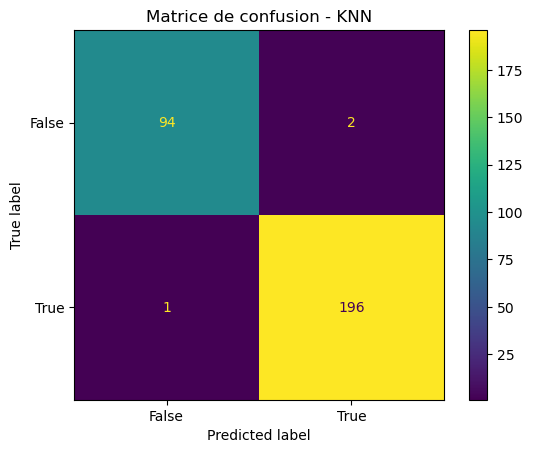

In [41]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred_knn)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["False", "True"]
).plot()

plt.title("Matrice de confusion - KNN")
plt.show()

In [42]:
from sklearn.ensemble import RandomForestClassifier

# hum... devinez ce qu'il faut faire 😁.

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=8
)

# Entraînement
rf.fit(X_train, y_train)

# Prédictions
y_pred_rf = rf.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred_rf)

print("Accuracy :", accuracy)

Accuracy : 0.9897610921501706


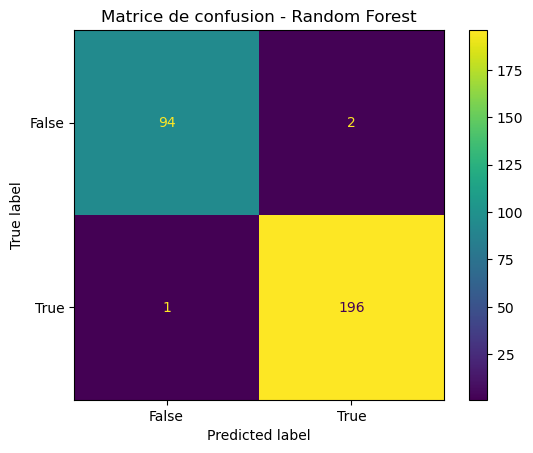

In [43]:
cm = confusion_matrix(y_test, y_pred_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["False", "True"]
).plot()

plt.title("Matrice de confusion - Random Forest")
plt.show()

In [44]:
feature_names = [
    "diagonal",
    "height_left",
    "height_right",
    "margin_low",
    "margin_up",
    "length"
]

importance = pd.Series(
    rf.feature_importances_,
    index=feature_names
).sort_values(ascending=False)

print(importance)

length          0.492913
margin_low      0.340410
margin_up       0.095992
height_right    0.038610
height_left     0.024360
diagonal        0.007716
dtype: float64


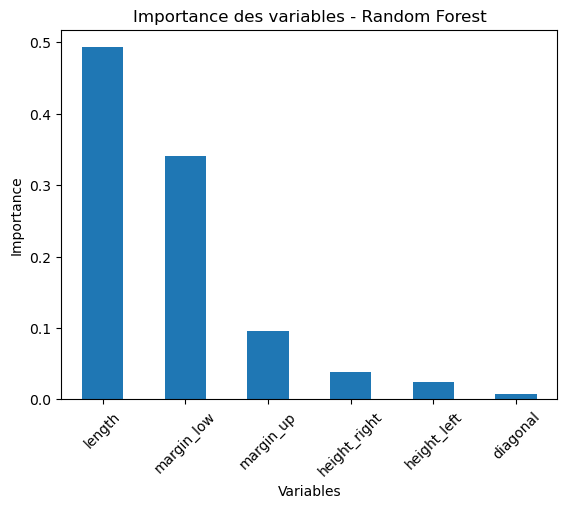

In [45]:
importance.plot(kind="bar")

plt.title("Importance des variables - Random Forest")
plt.xlabel("Variables")
plt.ylabel("Importance")
plt.xticks(rotation=45)
plt.show()

In [46]:
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import fcluster, linkage
# Attention ! Cet algo est très différents de ceux utilisés précédemment.
# Peux-tu voir les différences ?
# Du coup, cet algo est-il utile (voir pertinent) pour cette étude ?

In [47]:
k_range = range(2, 8)
silhouette_scores = []

In [48]:
for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = kmeans.fit_predict(X)

    # Calcul du score moyen pour l'ensemble des données
    score = silhouette_score(X, cluster_labels)
    silhouette_scores.append(score)
    print(f"Pour K = {k}, le score de silhouette moyen est : {score:.4f}")

Pour K = 2, le score de silhouette moyen est : 0.3424
Pour K = 3, le score de silhouette moyen est : 0.2115
Pour K = 4, le score de silhouette moyen est : 0.1980
Pour K = 5, le score de silhouette moyen est : 0.1564
Pour K = 6, le score de silhouette moyen est : 0.1504
Pour K = 7, le score de silhouette moyen est : 0.1455


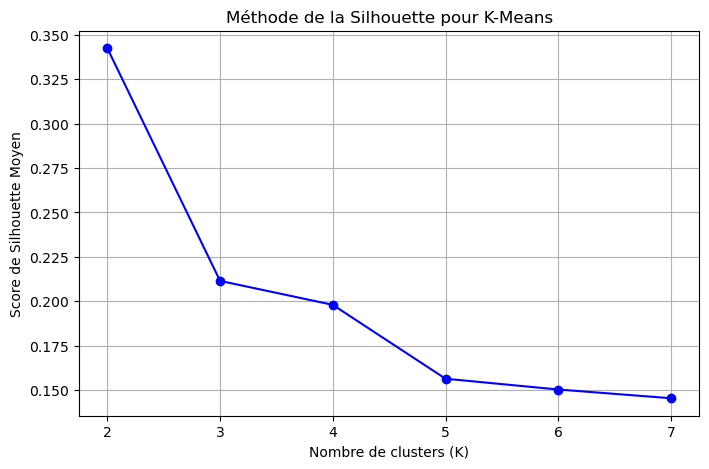

In [49]:
plt.figure(figsize=(8, 5))
plt.plot(k_range, silhouette_scores, marker="o", linestyle="-", color="b")
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Score de Silhouette Moyen")
plt.title("Méthode de la Silhouette pour K-Means")
plt.grid(True)
plt.show()

In [50]:
k = 2

In [51]:
Z = linkage(X_test, method="ward")
Z[:10]

clusters = fcluster(Z, k, criterion='maxclust')
clusters

array([1, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       1, 2, 2, 1, 2, 2, 2, 1, 1, 1, 1, 2, 2, 1, 2, 2, 1, 2, 2, 1, 2, 2,
       2, 2, 1, 1, 2, 1, 1, 2, 2, 1, 2, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 1,
       1, 2, 2, 2, 2, 1, 1, 2, 2, 1, 2, 2, 2, 1, 1, 2, 2, 1, 2, 2, 2, 1,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 1, 2, 2, 1, 2, 2, 2, 2, 2, 1,
       2, 2, 2, 2, 2, 2, 2, 2, 1, 1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1,
       2, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 1, 1, 1, 2, 2, 2, 2, 1, 2, 2, 1,
       1, 2, 2, 2, 1, 1, 2, 2, 1, 2, 1, 2, 1, 1, 1, 2, 1, 2, 2, 2, 1, 1,
       2, 1, 2, 2, 2, 1, 1, 1, 2, 1, 2, 2, 1, 1, 2, 1, 2, 2, 2, 2, 2, 1,
       2, 1, 2, 1, 2, 2, 2, 1, 1, 2, 2, 1, 1, 1, 2, 2, 2, 2, 2, 2, 1, 2,
       1, 2, 2, 2, 1, 2, 2, 2, 2, 2, 1, 1, 2, 1, 1, 2, 1, 1, 1, 2, 1, 2,
       1, 2, 2, 1, 2, 2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 2, 1, 1, 1, 1, 2,
       2, 2, 2, 2, 2, 1, 2, 2, 1, 2, 1, 2, 1, 2, 2, 1, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 1, 2, 2, 2], dtype=int32)

In [52]:
crosstab = pd.crosstab(y_test, clusters, dropna=False)
crosstab.rename_axis(columns="cluster", inplace=True)
crosstab

cluster,1,2
is_genuine,,
False,95,1
True,5,192


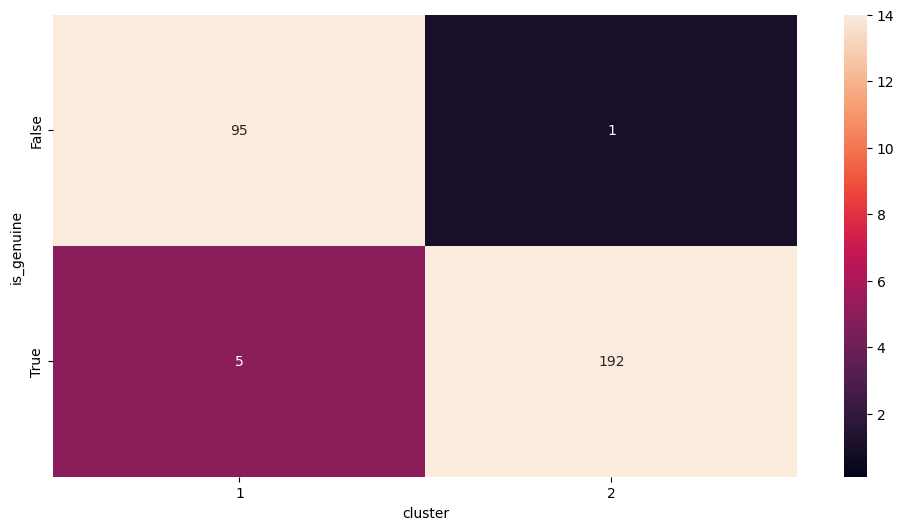

In [53]:
fig, ax = plt.subplots(1,1, figsize=(12,6))
ax = sns.heatmap(crosstab, vmin=0.1, vmax=14, fmt="d", annot=True)

# Sélection du meilleur modèle

Mais alors, quel est le meilleur modèle pour résoudre ce problème ?

Pour répondre à cette question, il vous faut bien comprendre l'intérêt de chacune des métriques d'évaluation qui existent pour ce type de problème.

Vous me voyez venir... 😎 : StatQuest !!! 🤩
* [Machine Learning Fundamentals: Sensitivity and Specificity
](https://youtu.be/vP06aMoz4v8)
* [Machine Learning Fundamentals: The Confusion Matrix](https://youtu.be/Kdsp6soqA7o)
* [ROC and AUC, Clearly Explained!](https://youtu.be/4jRBRDbJemM)

Vous avez aussi des petits modules sympathiques sur Sklearn qui vous machent grandement le travail:
* [Confusion Matrix](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html)
* [Confusion Matrix Display](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html)
* [Classification Report](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html)

A vous de jouer ! 🚀

In [54]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

# C'est là qu'on voit qui sont les bons 😉!

results = []

models = {
    "Logistic Regression": logreg,
    "Random Forest": rf,
    "KNN": knn
}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_proba = model.predict_proba(X_test)[:, 1]

    results.append({
        "Modèle": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_proba)
    })

results_df = pd.DataFrame(results)
results_df

,Modèle,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.989761,0.989899,0.994924,0.992405,0.999365
1,Random Forest,0.989761,0.989899,0.994924,0.992405,0.999392
2,KNN,0.989761,0.989899,0.994924,0.992405,0.994051


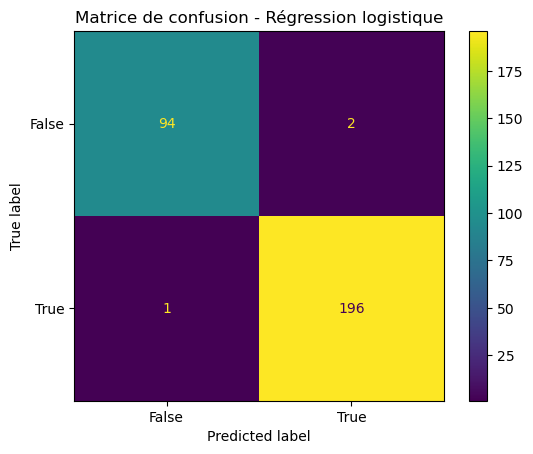

In [55]:
cm = confusion_matrix(y_test, y_pred_logreg)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["False", "True"]
).plot()

plt.title("Matrice de confusion - Régression logistique")
plt.show()

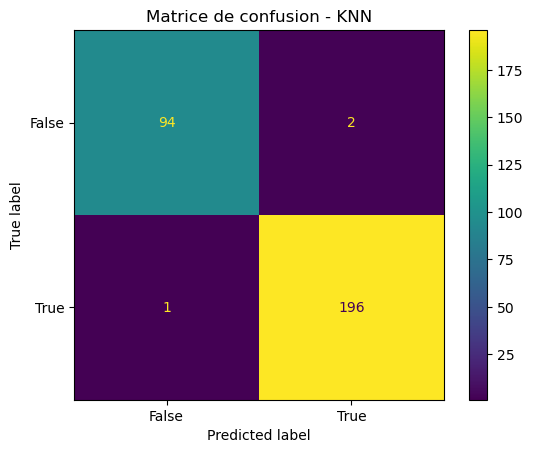

In [56]:
cm = confusion_matrix(y_test, y_pred_knn)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["False", "True"]
).plot()

plt.title("Matrice de confusion - KNN")
plt.show()

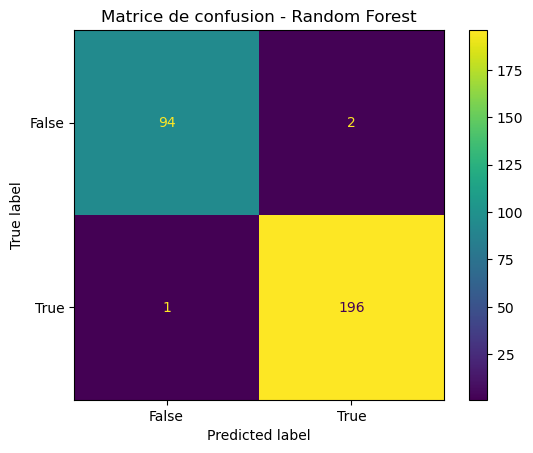

In [57]:
cm = confusion_matrix(y_test, y_pred_rf)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["False", "True"]
).plot()

plt.title("Matrice de confusion - Random Forest")
plt.show()

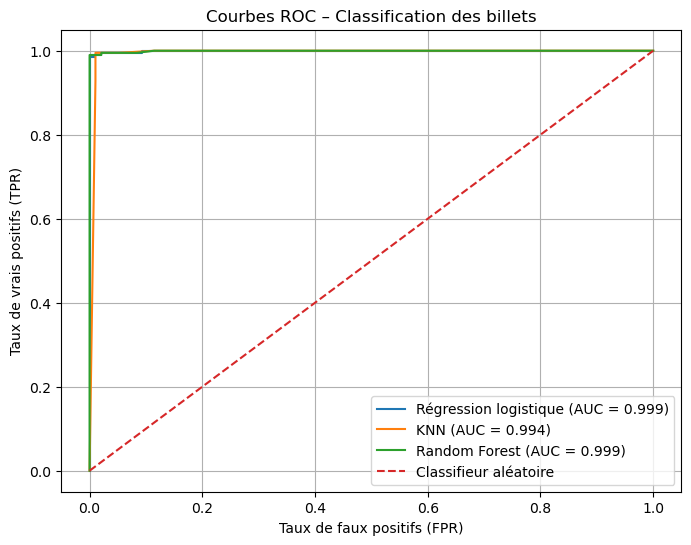

In [58]:
from sklearn.metrics import roc_curve

# Probabilités de la classe True
y_proba_logreg = logreg.predict_proba(X_test)[:, 1]
y_proba_knn = knn.predict_proba(X_test)[:, 1]
y_proba_rf = rf.predict_proba(X_test)[:, 1]

# Courbes ROC
fpr_logreg, tpr_logreg, _ = roc_curve(y_test, y_proba_logreg)
fpr_knn, tpr_knn, _ = roc_curve(y_test, y_proba_knn)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

# AUC
auc_logreg = roc_auc_score(y_test, y_proba_logreg)
auc_knn = roc_auc_score(y_test, y_proba_knn)
auc_rf = roc_auc_score(y_test, y_proba_rf)

# Graphique
plt.figure(figsize=(8, 6))

plt.plot(
    fpr_logreg,
    tpr_logreg,
    label=f"Régression logistique (AUC = {auc_logreg:.3f})"
)

plt.plot(
    fpr_knn,
    tpr_knn,
    label=f"KNN (AUC = {auc_knn:.3f})"
)

plt.plot(
    fpr_rf,
    tpr_rf,
    label=f"Random Forest (AUC = {auc_rf:.3f})"
)

# Modèle aléatoire
plt.plot([0, 1], [0, 1], linestyle="--", label="Classifieur aléatoire")

plt.xlabel("Taux de faux positifs (FPR)")
plt.ylabel("Taux de vrais positifs (TPR)")
plt.title("Courbes ROC – Classification des billets")
plt.legend()
plt.grid()

plt.show()

In [59]:
print(classification_report(y_test, y_pred_logreg))

              precision    recall  f1-score   support

       False       0.99      0.98      0.98        96
        True       0.99      0.99      0.99       197

    accuracy                           0.99       293
   macro avg       0.99      0.99      0.99       293
weighted avg       0.99      0.99      0.99       293



In [60]:
print(classification_report(y_test, y_pred_knn))

              precision    recall  f1-score   support

       False       0.99      0.98      0.98        96
        True       0.99      0.99      0.99       197

    accuracy                           0.99       293
   macro avg       0.99      0.99      0.99       293
weighted avg       0.99      0.99      0.99       293



In [61]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

       False       0.99      0.98      0.98        96
        True       0.99      0.99      0.99       197

    accuracy                           0.99       293
   macro avg       0.99      0.99      0.99       293
weighted avg       0.99      0.99      0.99       293



In [62]:
print(model)
print(type(model))
print(model.classes_)
df["is_genuine"].value_counts()

KNeighborsClassifier(n_neighbors=8)
<class 'sklearn.neighbors._classification.KNeighborsClassifier'>
[False  True]


is_genuine
True     1000
False     500
Name: count, dtype: int64

# Sauvegarde du meilleur modèle

**_ATTENTION_** :
```
Sauvegarder un modèle implique de sauvegarder aussi les étapes de préprocessing des données.
Dans votre cas, vous devez donc inclure, à minima, votre StandardScaler.
```
Voir [`make_pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html) pour plus d'infos.

Dans le chapitre précédent, nous avons vu que les trois modèles de prédiction (régression logistique, knn, et random forest) avaient des résultats identiques concernant l'Accuracy, la Precision, le Recall, et le F1. Seul le ROC-AUC peut déterminer quel modèle est le meilleur. Dans notre cas, c'est le modèle de Random Forest qui obtient de très peu les meilleurs résultats.

In [63]:
from sklearn.pipeline import make_pipeline
import joblib

# Utilisez make_pipeline pour inclure toutes les étapes nécessaires
# à la prédiction de si un billet est vrai ou faux.

model = make_pipeline(
    StandardScaler(),
    RandomForestClassifier(
        n_estimators=100,
        random_state=8
    )
)

# Entraînement

model.fit(X_train, y_train)

# Sauvegardez votre modèle à l'aide de la librairie joblib.

joblib.dump(model, "modele_billets.pkl")

['modele_billets.pkl']